In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("https://raw.githubusercontent.com/campusx-official/100-days-of-machine-learning/refs/heads/main/day42-outlier-removal-using-zscore/placement.csv")

In [3]:
df.shape

(1000, 3)

In [4]:
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


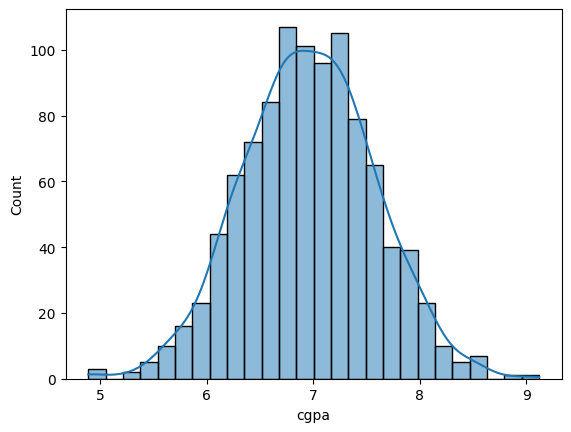

In [5]:
sns.histplot(df["cgpa"],kde=True)
plt.show()

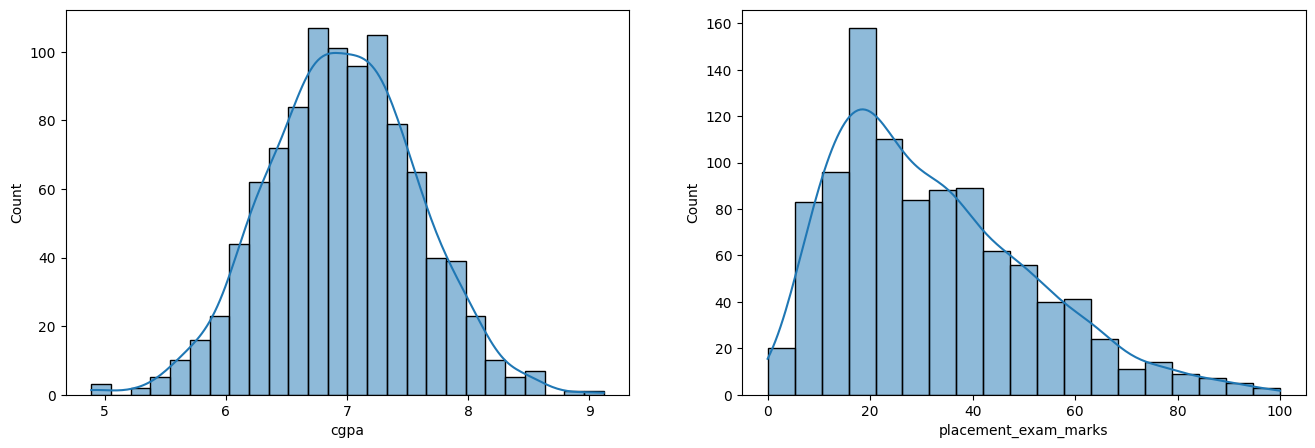

In [6]:
plt.figure(figsize=(16,5))

plt.subplot(1,2,1)
sns.histplot(df["cgpa"],kde=True)

plt.subplot(1,2,2)
sns.histplot(df["placement_exam_marks"],kde=True)

plt.show()

In [7]:
df["cgpa"].describe()

,cgpa
count,1000.000000
mean,6.961240
std,0.615898
min,4.890000
25%,6.550000
50%,6.960000
75%,7.370000
max,9.120000


In [8]:
print("Highest",df["cgpa"].mean() + 3*df["cgpa"].std())
print("lowest",df["cgpa"].mean() - 3*df["cgpa"].std())

Highest 8.808933625397168
lowest 5.113546374602832


In [9]:
df[(df["cgpa"] > 8.808933625397168) | (df["cgpa"] < 5.113546374602832)]

,cgpa,placement_exam_marks,placed
485,4.92,44.0,1
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
999,4.90,10.0,1


In [10]:
# Trimming

new_df=df[(df["cgpa"] <  8.80) & (df["cgpa"]>5.11)]
new_df.shape

(995, 3)

In [18]:
# Calculating Z-Score

df["cgpa_z-score"]=(df["cgpa"]-df["cgpa"].mean())/df["cgpa"].std()

In [19]:
df.head()

,cgpa,placement_exam_marks,placed,cgpa_z-score
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371


In [21]:
df[(df["cgpa_z-score"] > 3) | (df["cgpa_z-score"] < -3)]

,cgpa,placement_exam_marks,placed,cgpa_z-score
485,4.92,44.0,1,-3.314251
995,8.87,44.0,1,3.099150
996,9.12,65.0,1,3.505062
997,4.89,34.0,0,-3.362960
999,4.90,10.0,1,-3.346724


In [22]:
new_df=df[(df["cgpa_z-score"]>-3) & (df["cgpa_z-score"] < 3)]

In [23]:
new_df.head()

,cgpa,placement_exam_marks,placed,cgpa_z-score
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371


In [24]:
new_df.shape

(995, 4)

Capping

In [25]:
upper_limit=df["cgpa"].mean() +3*df["cgpa"].std()
lower_limit=df["cgpa"].mean() - 3*df["cgpa"].std()

In [26]:
upper_limit

np.float64(8.808933625397168)

In [27]:
lower_limit

np.float64(5.113546374602832)

In [28]:
df["cgpa"]=np.where(df["cgpa"]>upper_limit,upper_limit,
                   np.where(df["cgpa"]<lower_limit,lower_limit,
                            df["cgpa"]
                            ) )

In [29]:
df["cgpa"].describe()

,cgpa
count,1000.000000
mean,6.961499
std,0.612688
min,5.113546
25%,6.550000
50%,6.960000
75%,7.370000
max,8.808934
